First, we install necessary libraries.

In [1]:
%pip install -r lib/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# First Order Methods - 30 points

Following the regularized formulation in [Part 1, equation (2)](Part%201%20-%20Theory.ipynb#eq-regularized-estimator), we now consider binary logistic regression. Here $f$ is the average negative log-likelihood over the $n$ samples, as implemented by the helper function. We solve:

<a id="eq-binary-objective"></a>

$$
	\mathbf{x}^\star=\arg\min_{\mathbf{x} \in \mathbb{R}^p} f_\mu(\mathbf{x}), \qquad f_\mu(\mathbf{x}) := f(\mathbf{x}) + \frac{\mu}{2}\|\mathbf{x}\|_2^2.
\tag{3}
$$

The optimality condition of [(3)](#eq-binary-objective) is

<a id="eq-optimality"></a>

$$
\nabla f_\mu({\mathbf x}^\star) = \frac{1}{n}\sum_{i=1}^n -b_i \sigma(-b_i \cdot \mathbf{a}_i^T\mathbf{x}^\star)\mathbf{a}_i + \mu \mathbf{x}^\star = 0. \tag{4}
$$

Thanks to convexity, condition [(4)](#eq-optimality) is in fact the necessary and sufficient condition for $\mathbf x^\star$ to be optimal.
We can equivalently write this condition as

<a id="eq-fixed-point"></a>

$$
\mathbf x^\star = {\mathbf x}^\star - \mathbf{B} \nabla f_\mu({\mathbf x}^\star) \tag{5}
$$

for any symmetric, positive definite matrix $\mathbf{B}$. 
This is a fixed-point formulation of [(3)](#eq-binary-objective), which will be used to develop first-order methods.


Notice that choosing $\mathbf{B} = \alpha \mathbb{I}$ with $\alpha > 0$ in the formulation [(5)](#eq-fixed-point) suggests that the gradient descent method can be used to solve [(3)](#eq-binary-objective). 

In this part, you will implement different variants of the gradient descent algorithm. 


### Code structure:

A `Function` is a type that has the following attributes:

```python
@dataclass
class Function:
    f              # The function that is being minimized
    grad           # The gradient of the function
    minimum        # The minimum value of the function
    strng_cvx      # The strong convexity constant, if it admits one
    lips_grad      # The smoothness constant, if it admits one
```

For a provided `Function` object `f`:
- You can evaluate the function at a point `x` by simply writing `f(x)`.
- You can evaluate the gradient at a point `x` by writing `f.grad(x)`.
- You can get the smoothness constant by writing `f.lips_grad`.
- You can get the strong convexity constant by writing `f.strng_cvx`



The helper provides the objective $f_\mu$ as the object `f` and an initial point `x_zero`.

In [3]:
from lib.part_one import f, x_zero

The provided `test` function runs a method on the strongly convex quadratic $x \mapsto \frac{1}{2}x^\top M x$, starting from $x_0 = \begin{bmatrix} 100.0& 100.0 \end{bmatrix}$. By default, it runs 100 iterations. For example, after implementing `GD`, run

```python
test(GD)
```

<div class="alert alert-block alert-success">
<b>Run the cells in order.</b> Later cells use variables defined in earlier cells.
</div>

### Variants of Gradient Descent

Now you will implement various methods to iteratively improve the initial guess `x_zero`.

__(a)__ (2 points) The main ingredients of the gradient descent algorithm are the descent direction (the negative gradient) and the step-size $\alpha_k$. 
In this part, we consider the gradient descent algorithm with constant step-size ${1}/{L}$, i.e., $\alpha_k = {1}/{L}$ for any $k = 0,1,...$ where $L$ is the gradient-Lipschitz constant of the function `f`. 

Gradient Descent, as an iterative scheme, only tracks the current iterate `x_k` and the step size `alpha_k`. We store them both in a state variable that holds both these attributes:

In [4]:
@dataclass
class GD_state(OptState):
    x_k: Vector
    alpha_k: float

Given a function `f` and a state at some iteration $k$, recall how GD updates the state and fill in the following cell:

In [5]:
def GD_update(f, state):
    x_k, alpha_k = state
    x_next = x_k - alpha_k * f.grad(x_k)  # FILL
    return GD_state(x_k=x_next, alpha_k=alpha_k)


Having defined the `GD_update` which updates a given state, we now need to initialize the state. Fill in the cell below, recalling that you are given an initial guess `x_zero`, and the fact that we are using a fixed step size corresponding to the smoothness constant of `f`.

In [6]:
def GD_initialize(f, x_zero):
    x_k = x_zero  # FILL
    alpha_k = 1 / f.lips_grad  # FILL
    return GD_state(x_k, alpha_k)


With the initialization and the update scheme specified, we define the algorithm in the cell below:

In [7]:
GD = OptAlgorithm(name="GD", init_state = GD_initialize, state_update = GD_update)

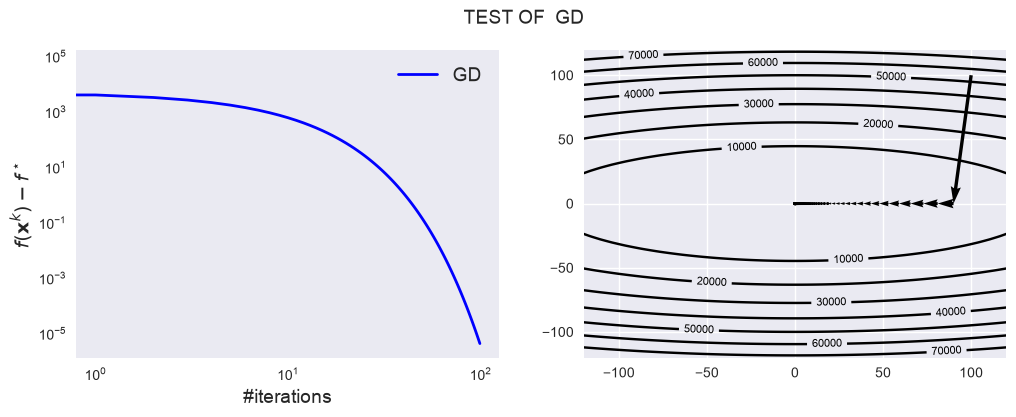

In [8]:
test(GD)

We now notice that the objective function is strongly convex. Therefore, we can select the constant step-size $\alpha$ as $2/(L+\mu)$ to get a faster convergence rate. We call this algorithm `GDstr`.

Both `GD` and `GDstr` have the same state update but only differ in the stepsize they use. Implement this variant of the gradient descent method by completing the code:

In [9]:
def GDstr_initialize(f, x_zero):
    x_k = x_zero  # FILL
    alpha_k = 2 /(f.lips_grad + f.strng_cvx)  # FILL
    return GD_state(x_k, alpha_k)

GDstr = OptAlgorithm(name="GDstr", init_state=GDstr_initialize, state_update=GD_update)


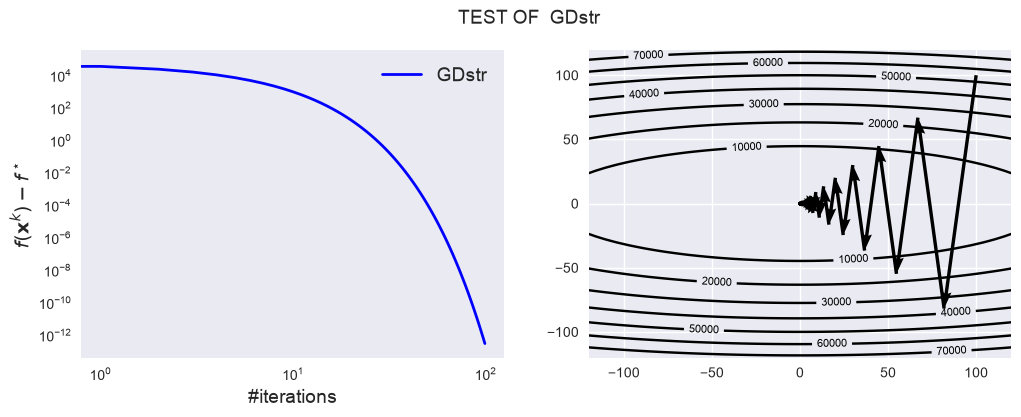

In [10]:
test(GDstr)

__(b-1)__ (1.5 points) We can accelerate the above gradient descent algorithm with the following scheme ($t_0=1$):

$$
\begin{array}{ll}
\mathbf{x}^{k+1} &:=  \mathbf{y}^k - \alpha_k\nabla{f_\mu}(\mathbf{y}^k),\\
t_{k+1} &:= \frac{1}{2}(1 + \sqrt{1 + 4t_k^2})\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + \frac{t_k-1}{t_{k+1}}\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{array}
$$

Implement this algorithm with constant step-size $\alpha = 1/L$, by completing the missing parts of the following cells.

First we define the state that the algorithm updates at each iteration:

In [11]:
@dataclass
class AGD_state(OptState):
    x_k: Vector
    y_k: Vector
    t_k: float
    alpha_k: float

Given this `state` and a function `f` to optimize, write the update step of accelerated gradient descent:

In [12]:
def AGD_update(f, state):
    x_k, y_k, t_k, alpha_k = state
    next_x_k = y_k - alpha_k * f.grad(y_k)  # FILL
    next_t_k = (1 + np.sqrt(1 + 4*(t_k**2))) / 2  # FILL
    next_y_k = next_x_k + ((t_k -1 )/ next_t_k) * (next_x_k - x_k)  # FILL
    next_alpha_k = alpha_k  # FILL
    return AGD_state(next_x_k, next_y_k, next_t_k, next_alpha_k)


Define the initial state of AGD in the cell below:

In [13]:
def AGD_initialize(f, x_zero):
    x_k = x_zero
    y_k = x_zero
    t_k = 1.0
    alpha_k = 1 / f.lips_grad
    # FILL
    return AGD_state(x_k, y_k, t_k, alpha_k)

We have all the necessary ingredients to define the optimization algorithm in the following cell:

In [14]:
AGD = OptAlgorithm(name="AGD", init_state=AGD_initialize, state_update=AGD_update)

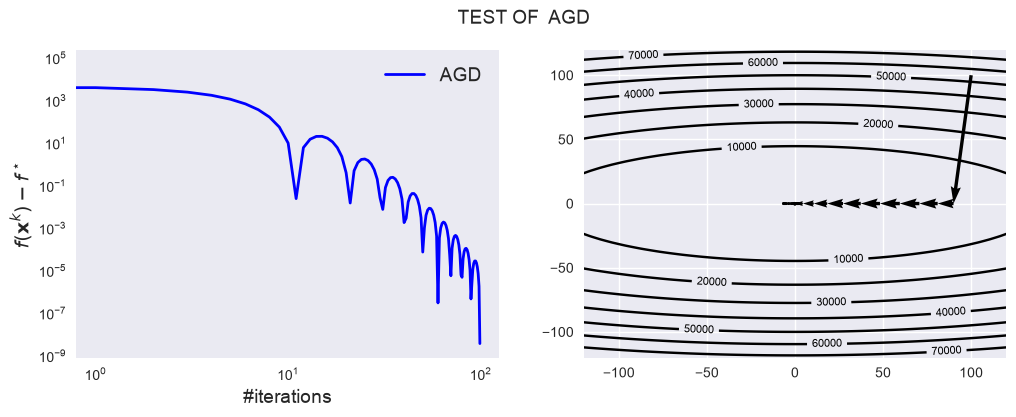

In [15]:
test(AGD)

__(b-2)__ (1 point)

Note that the objective function is strongly convex. Therefore, we can use the accelerated gradient algorithm for strongly convex objectives to converge faster. This variant can be summarized as follows:

$$
\left\{
\begin{aligned}
\mathbf{x}^{k+1} &:= \mathbf{y}^k - \alpha_k \nabla f_\mu(\mathbf{y}^k),\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + m\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{aligned}
\right.
$$
 
Implement this variant of the accelerated gradient method by completing the following cells. Try different values of $m$ and comment on what should be the best value for this constant. Do the practical results follow the theory?

In [16]:
@dataclass
class AGDstr_state(OptState):
    x_k: Vector
    y_k: Vector
    alpha_k: float
    m_strongcvx: float

In [17]:
def AGDstr_update(f, state):
    x_k, y_k, alpha_k, m_strongcvx = state
    next_x_k = y_k - alpha_k * f.grad(y_k) # FILL
    next_y_k = next_x_k + m_strongcvx * (next_x_k - x_k)  # FILL
    return AGDstr_state(next_x_k, next_y_k, alpha_k, m_strongcvx)


def AGDstr_initialize(f, x_zero):
    m_strongcvx = (np.sqrt(f.lips_grad) - np.sqrt(f.strng_cvx)) / (np.sqrt(f.lips_grad) + np.sqrt(f.strng_cvx)) # FILL: choose m and compare different values. 
    # m chosen from lecture 5 (slide 6)
    x_k = x_zero
    y_k = x_zero
    alpha_k = 1 / f.lips_grad
    # FILL
    return AGDstr_state(x_k, y_k, alpha_k, m_strongcvx)

In [18]:
AGDstr = OptAlgorithm(name="AGDstr", init_state=AGDstr_initialize, state_update=AGDstr_update)

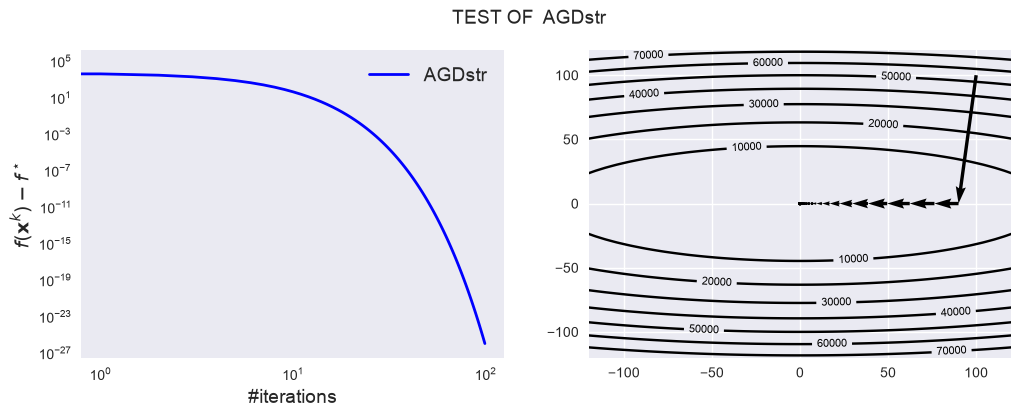

In [19]:
test(AGDstr)

In [20]:
# FILL: compare different values of m.
# As said above, the best m value according to theory is

print((np.sqrt(f.lips_grad) - np.sqrt(f.strng_cvx)) / (np.sqrt(f.lips_grad) + np.sqrt(f.strng_cvx)))

0.999698770722138


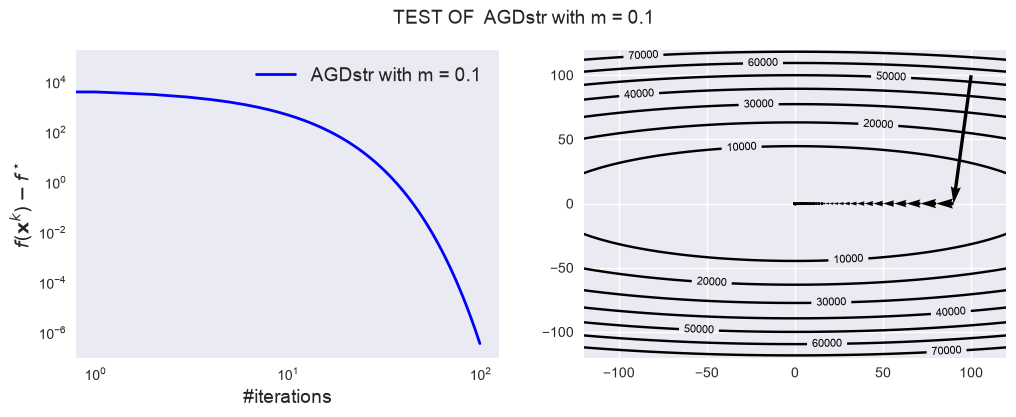

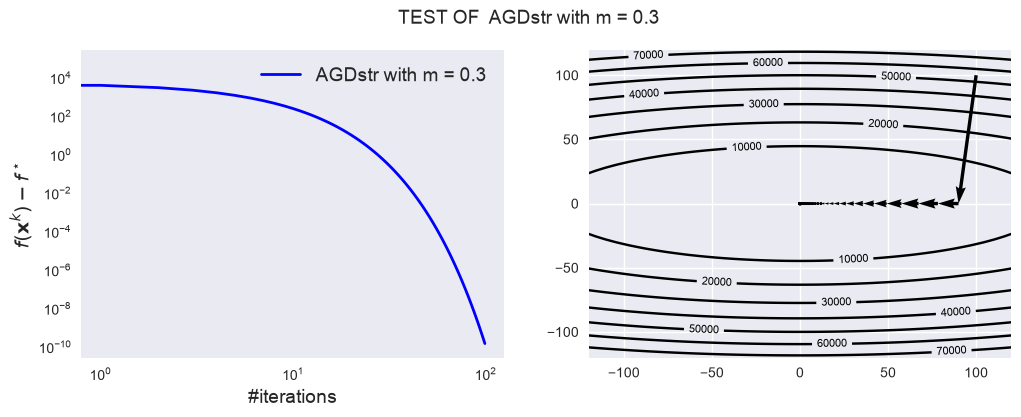

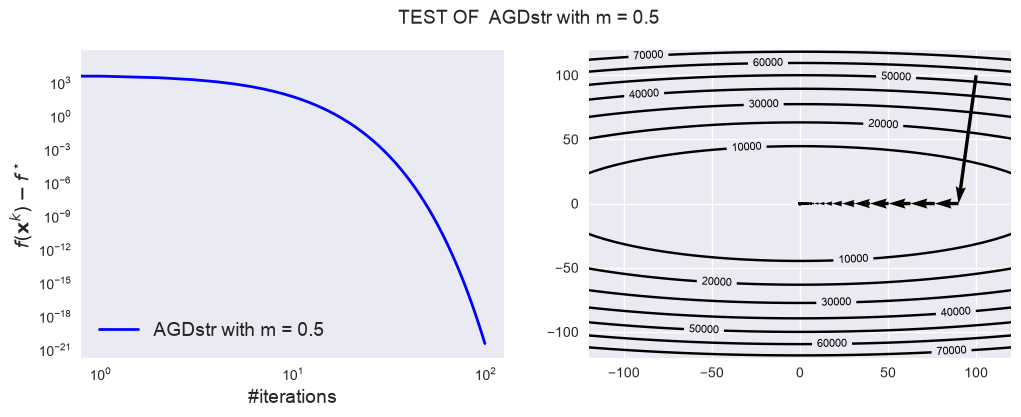

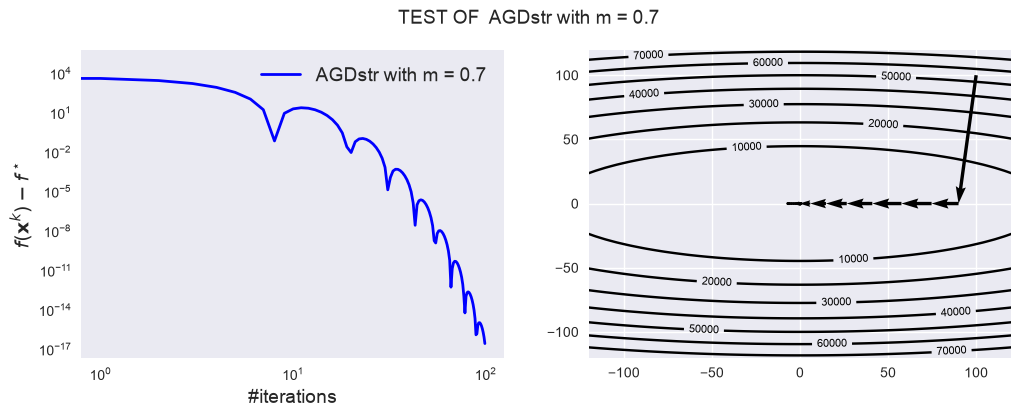

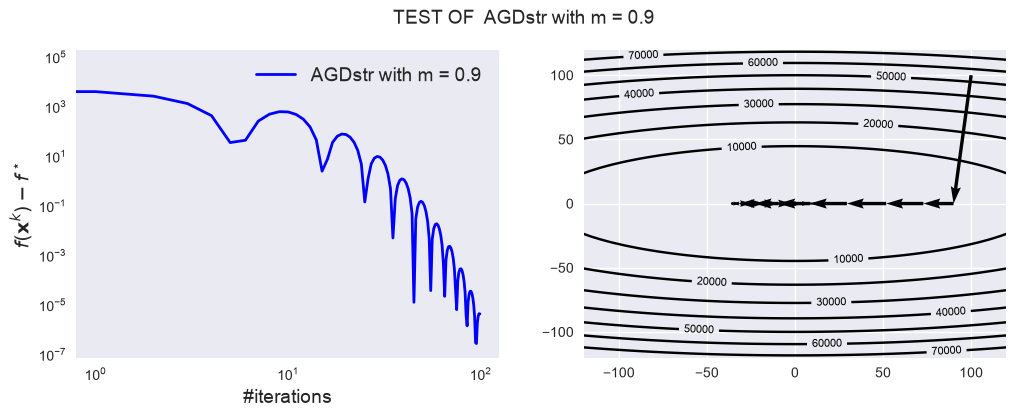

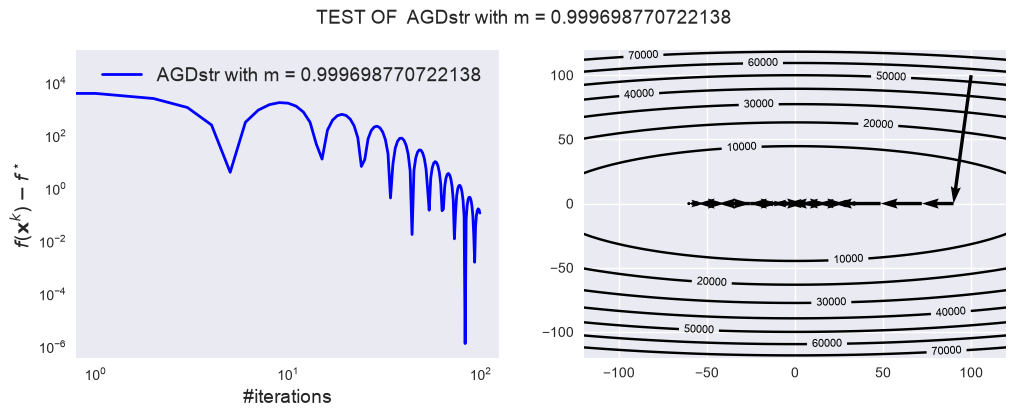

In [24]:
# We could then try to run the algorithm using a range of arbitrary values for m and compare it to the best one in theory

m_best = (np.sqrt(f.lips_grad) - np.sqrt(f.strng_cvx)) / (np.sqrt(f.lips_grad) + np.sqrt(f.strng_cvx))
m_values = [0.1, 0.3, 0.5, 0.7, 0.9, m_best]

def AGDstr_initialize_comparison(f, x_zero):
    m_strongcvx = m
    x_k = x_zero
    y_k = x_zero
    alpha_k = 1 / f.lips_grad
    return AGDstr_state(x_k, y_k, alpha_k, m_strongcvx)

for m in m_values:
    test(OptAlgorithm(name=f"AGDstr with m = {m}", init_state=AGDstr_initialize_comparison, state_update=AGDstr_update))

***Discussion.***
It looks like practical results do not follow theory, as a matter of fact the convergence seems to improve by increasing m until we reach the value of m = 0.5, after that, the order of magnitude of the distance from the optimum $f(\mathbf{x}^k)-f^\star$ increases with m. In fact, the theoretically best value of m performs the worst within the 100 plotted iterations, possibly because of the fact that the momentum becomes too large and causes the algorithm to overshoot forcing the trajectory to go back and forth (clearly visible in the right side plots) making convergence slower. 

__(c)__ (5 points) We can obtain better performance by considering a line search procedure, which adapts the step-size $\alpha_k$ to the local geometry. 
The line-search strategy to determine the step-size $\alpha_k$ for the standard GD algorithm,
$\mathbf{x}^{k+1}=\mathbf{x}^k-\alpha_k\nabla f_\mu(\mathbf{x}^k),$
is the following: 

Initialize $L_{-1}=L$. At iteration $k\geq0$, use the current iterate $\mathbf{x}^k$ and descent direction $\mathbf{d}^k=-\nabla f_\mu(\mathbf{x}^k)$:

* At each iteration, set $L_{k,0} = \frac{1}{2}L_{k-1}$, where $k$ is the iteration counter. 
* Starting at $i=0$ and increasing $i$ as needed, find the minimum integer $i \geq 0$ that satisfies $f_\mu\left(\mathbf{x}^k + \frac{1}{2^i L_{k,0}} \mathbf{d}^k\right) \leq f_\mu(\mathbf{x}^k) -\frac{1}{2^{i+1} L_{k,0}} \|\mathbf{d}^k\|^2$.
* Set $L_k = {2^i L_{k,0}}$ and use the step-size $\alpha_k := \frac{1}{L_k}$ to take the accepted gradient step.

Complete the missing parts in order to implement gradient descent with line-search.

In [21]:
@dataclass
class LS_GD_state(OptState):
    x_k : Vector
    L_k : float
    alpha_k : float

In [22]:
def LS_GD_update(f, state):
    x_k, L_k, _ = state
    
    L_k_zero = L_k / 2
    i = 0 
    i_min = None
    d_k = - f.grad(x_k)
    d_k_norm = d_k @ d_k
    while i_min is None :
        left = f(x_k + d_k / (2**i * L_k_zero))
        right = f(x_k) - d_k_norm / (2**(i+1) * L_k_zero)
        if left <= right :
            i_min = i
            break
        i += 1
    
    next_L_k = (2**i_min) * L_k_zero
    alpha_k = 1 / next_L_k
    next_x_k = x_k + alpha_k * d_k
    # FILL
    return LS_GD_state(next_x_k, next_L_k, alpha_k)
    
def LS_GD_initialize(f, x_zero):
    x_k = x_zero
    L_k = f.lips_grad
    alpha_k = 1 / L_k # not necessary
    # FILL
    return LS_GD_state(x_k, L_k, alpha_k)


In [23]:
LS_GD = OptAlgorithm(name="LS_GD", init_state = LS_GD_initialize, state_update=LS_GD_update )

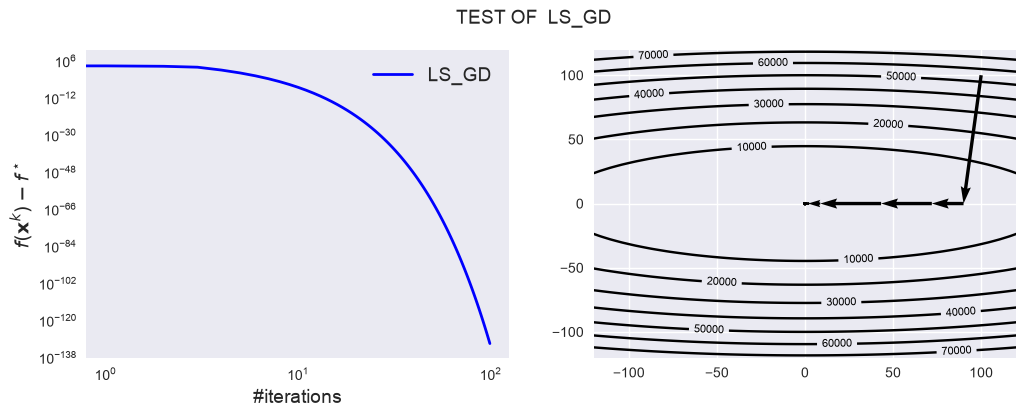

In [24]:
test(LS_GD)

We now incorporate a line-search enhancement to the accelerated gradient method implemented in (b-1). At iteration $k$, 
we have the current iterate $\mathbf{x}^k$ together with an _intermediate variable_ $\mathbf{y}^k$ and its corresponding direction $\mathbf{d}^k=-\nabla f_\mu(\mathbf{y}^k)$. **Note that the intermediate variable is then used in the gradient step and hence the line-search will be performed on it to determine the step-size**.


Perform a line-search strategy with respect to $\mathbf{y}^k$ and direction $\mathbf{d}^k$ to determine the step-size $\alpha_k$ as follows:

Initialize $L_{-1}=L$. Then, for $k\geq0$:

* At each iteration, set $L_{k,0} = \frac{1}{2}L_{k-1}$, where $k$ is the iteration counter. 
* Starting at $i=0$ and increasing $i$ as needed, find the minimum integer $i \geq 0$ that satisfies $f_\mu\left(\mathbf{y}^k + \frac{1}{2^i L_{k,0}} \mathbf{d}^k\right) \leq f_\mu(\mathbf{y}^k) -\frac{1}{2^{i+1} L_{k,0}} \|\mathbf{d}^k\|^2$.
* Set $L_k = {2^i L_{k,0}}$ and use the step-size $\alpha_k := \frac{1}{L_k}$.
 
Update the next iterations:
$$
\left\{
\begin{aligned}
\mathbf{x}^{k+1} &:= \mathbf{y}^k - \alpha_k \nabla f_\mu(\mathbf{y}^k),\\
t_{k+1} &:= \frac{1}{2}\left(1 + \sqrt{1 + 4\frac{L_k}{L_{k-1}}t_k^2}\right),\\
\mathbf{y}^{k+1} &:= \mathbf{x}^{k+1} + \frac{t_k-1}{t_{k+1}}\big(\mathbf{x}^{k+1} - \mathbf{x}^k\big).
\end{aligned}
\right.
$$

Complete the missing parts in order to implement accelerated gradient descent with line-search.

In [25]:
@dataclass
class LS_AGD_state(OptState):
    x_k : Vector
    y_k : Vector
    t_k : float
    L_k : float
    alpha_k : float


In [26]:
def LS_AGD_update(f, state):
    # FILL
    x_k, y_k, t_k, prev_L_k, _ = state
        
    L_k_zero = prev_L_k / 2
    i = 0 
    i_min = None
    d_k = - f.grad(y_k)
    d_k_norm = d_k @ d_k
    while i_min is None :
        left = f(y_k + d_k / (2**i * L_k_zero))
        right = f(y_k) - d_k_norm / (2**(i+1) * L_k_zero)
        if left <= right :
            i_min = i
            break
        i += 1
    
    L_k = (2**i_min) * L_k_zero
    alpha_k = 1 / L_k
    next_x_k = y_k + alpha_k * d_k
    next_t_k = (1 + np.sqrt(1 + 4 * (t_k**2) * L_k / prev_L_k))
    next_y_k = next_x_k + (t_k / next_t_k) * (next_x_k - x_k)
    # FILL
    return LS_AGD_state(next_x_k, next_y_k, next_t_k, L_k, alpha_k)
    

def LS_AGD_initialize(f, x_zero):
    # FILL
    x_k = x_zero
    y_k = x_zero
    t_k = 1.0
    L_k = f.lips_grad
    alpha_k = 1 / L_k # not necessary
    # FILL
    return LS_AGD_state(x_k, y_k, t_k, L_k, alpha_k)
    


In [27]:
LS_AGD = OptAlgorithm(name="LS_AGD", init_state=LS_AGD_initialize, state_update=LS_AGD_update )

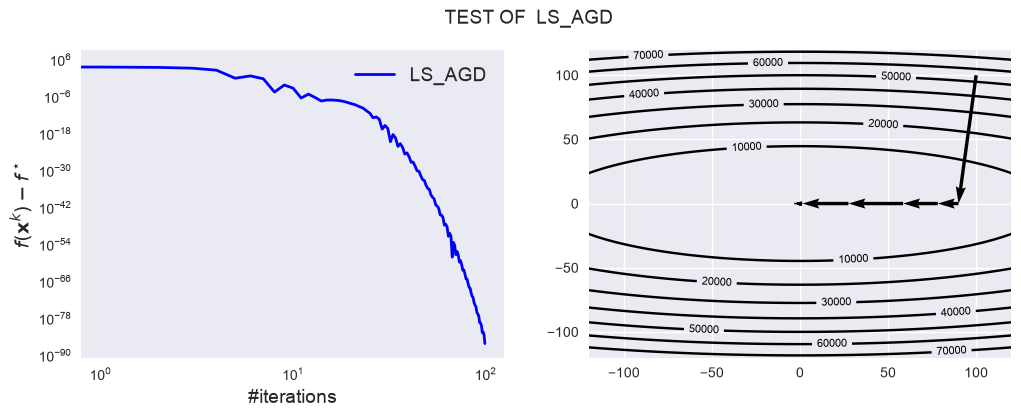

In [28]:
test(LS_AGD)

__(d)__ (3 points) The accelerated gradient method need not decrease the objective at every iteration: we may have $f_\mu(\mathbf{x}^{k+1})>f_\mu(\mathbf{x}^k)$ at some iterations.
To prevent such behavior, we can use the so-called adaptive restart strategy. 
In short, this strategy can be explained as follows: 
At each iteration, whenever $\mathbf{x}^{k+1}$ is computed, we evaluate $f_\mu(\mathbf{x}^{k+1})$ and compare it with $f_\mu(\mathbf{x}^k)$: 

* If $f_\mu(\mathbf{x}^k) < f_\mu(\mathbf{x}^{k+1})$, restart the iteration, i.e., recompute $\mathbf{x}^{k+1}$ by setting $\mathbf{y}^{k} := \mathbf{x}^{k}$ and $t_{k} := 1$;
* Otherwise, let the algorithm continue.


This strategy requires the evaluation of the function value at each iteration, which increases the computational complexity of the overall algorithm. 

Implement the adaptive restart strategy which uses the function values for the accelerated gradient algorithm with constant step-size $\alpha_k=1/L$ 
by completing the function:

In [29]:
@dataclass
class AGDR_state(AGD_state):
    # FILL
    x_k: Vector
    y_k: Vector
    t_k: float
    alpha_k: float

In [30]:
def AGDR_update(f, state):
    # FILL
    x_k, y_k, t_k, alpha_k = state
    next_x_k, next_y_k, next_t_k, next_alpha_k = AGD_update(f, state)
    if f(next_x_k) > f(x_k) :
        y_k = x_k
        t_k = 1
        next_x_k, next_y_k, next_t_k, next_alpha_k = AGD_update(f, AGD_state(x_k, y_k, t_k, alpha_k))

    return AGD_state(next_x_k, next_y_k, next_t_k, next_alpha_k)

AGDR_initialize = AGD_initialize

In [31]:
AGDR = OptAlgorithm(name="AGDR", init_state = AGDR_initialize, state_update=AGDR_update)

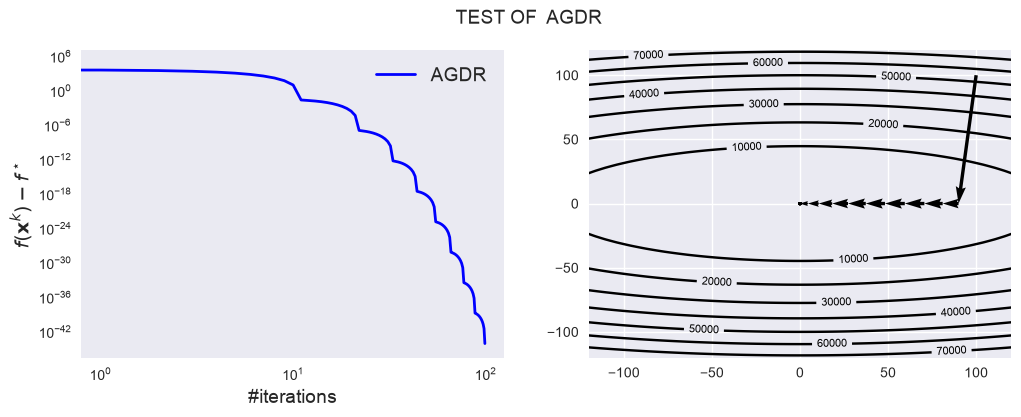

In [32]:
test(AGDR)

__(e)__ (Self-study, 0 points)
Combine line search, acceleration, and objective-based restart by completing `LS_AGDR_update`.

**Hint:** If the proposed step increases the objective, reset $\mathbf{y}^k=\mathbf{x}^k$ and $t_k=1$. Repeat the line search from this reset point and recompute the gradient step before updating the momentum.


In [33]:
@dataclass 
class LS_AGDR_state(LS_AGD_state):
    # FILL
    x_k : Vector
    y_k : Vector
    t_k : float
    L_k : float
    alpha_k : float


In [34]:
def LS_AGDR_update(f, state):
    # FILL
    x_k, y_k, t_k, prev_L_k, alpha_k = state
    next_x_k, next_y_k, next_t_k, L_k, alpha_k = LS_AGD_update(f, state)
    if f(next_x_k) > f(x_k) :
        y_k = x_k
        t_k = 1
        next_x_k, next_y_k, next_t_k, L_k, alpha_k = LS_AGD_update(f, LS_AGD_state(x_k, y_k, t_k, prev_L_k, alpha_k))  

    return LS_AGD_state(next_x_k, next_y_k, next_t_k, L_k, alpha_k)

LS_AGDR_initialize = LS_AGD_initialize

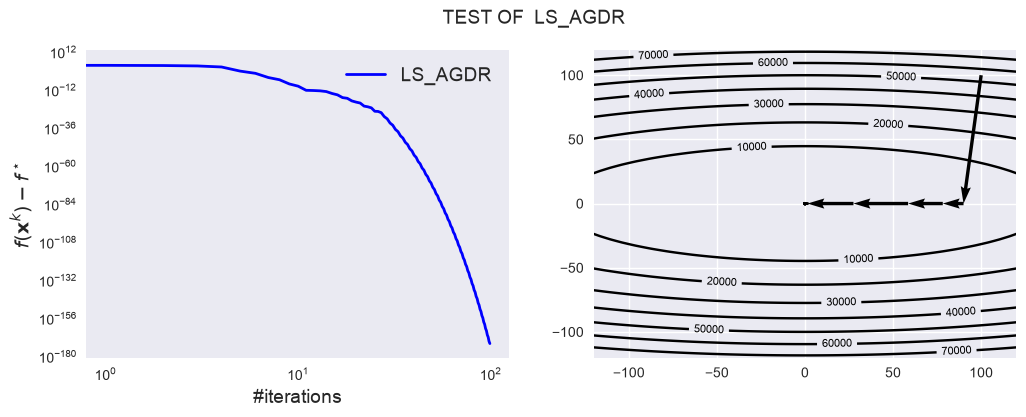

In [35]:
LS_AGDR = OptAlgorithm(name="LS_AGDR", init_state=LS_AGDR_initialize, state_update=LS_AGDR_update)

test(LS_AGDR)

__(f)__ (4 points) We can also apply an optimization technique that does not exploit the knowledge of the Lipschitz constant, and instead adapts to the local geometry by making use of past gradient information. This scalar AdaGrad variant divides the step size by the square root of the accumulated squared gradient norms. Starting with $Q_0 = 0$ it iterates as follows:

$$
\left\{\begin{array}{ll}
Q_{k+1} &{\!\!\!\!}= Q_k + \|\nabla f_\mu(\mathbf{x}^k)\|^2 \\
\mathbf{H}_k &{\!\!\!\!}= (\sqrt{Q_{k+1}} + \delta) I \\
\mathbf{x}^{k+1} &{\!\!\!\!}= \mathbf{x}^k - \alpha \mathbf{H}_k^{-1} \nabla f_\mu(\mathbf{x}^k)
\end{array}\right.
$$

Complete the missing parts in the function AdaGrad in order to implement the above adaptive gradient method using $\alpha = 1$, $\delta = 10^{-5}$.

In [36]:
@dataclass
class AdaGrad_state(OptState):
    # FILL
    x_k : Vector
    Q_k : float
    alpha : float
    delta : float


In [37]:
def AdaGrad_update(f, state):
    # FILL
        x_k, Q_k, alpha, delta = state ## doesn't work because Q_k and x_k are switched in utils
        #print("x_k = ", x_k, " supposed to be [100., 100.]")
        #print("Q_k = ", Q_k, " supposed to be 0.0")
        grad_x_k = f.grad(x_k)
        I = np.eye(len(x_k))
    
        next_Q_k = Q_k + grad_x_k @ grad_x_k
        H_k = (np.sqrt(next_Q_k) + delta) * I
        next_x_k = x_k - alpha * np.linalg.inv(H_k) @ grad_x_k
        #print(next_x_k.shape, x_k.shape, grad_x_k.shape) ## check shape
    
        return AdaGrad_state(next_x_k, next_Q_k, alpha, delta)

def AdaGrad_initialize(f, x_zero):
    Q_zero = 0
    x_k = x_zero
    alpha = 1
    delta = 1e-5
    
    return AdaGrad_state(x_k, Q_zero, alpha, delta)


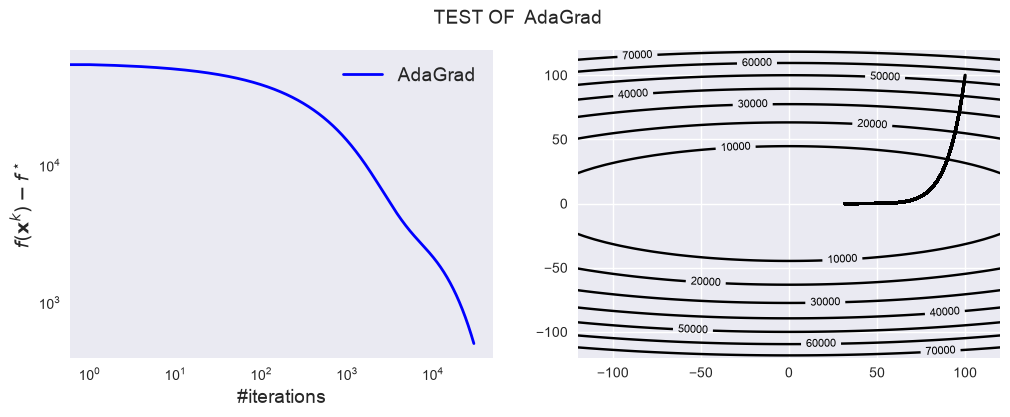

In [43]:
AdaGrad = OptAlgorithm(name="AdaGrad", init_state=AdaGrad_initialize, state_update=AdaGrad_update)
test(AdaGrad, maxiter=30000) ## need more than 140000

__(g)__ (2.5 points) Another famous adaptive optimization method is called the ADAptive Moment estimation algorithm, also known as ADAM, 

$$
\left\{\begin{array}{ll}
\mathbf{g}_k &{\!\!\!\!} = \nabla f_\mu(\mathbf{x}^{k}) \\
\mathbf{m}_{k+1} &{\!\!\!\!} = \beta_1 \mathbf{m}_{k} + (1-\beta_1)\mathbf{g}_k \ \textrm{$\leftarrow$ Momentum}\\
\mathbf{v}_{k+1} &{\!\!\!\!} = \beta_2 \mathbf{v}_{k} + (1-\beta_2)\mathbf{g}_k^2 \ \textrm{$\leftarrow$ Adaptive term}\\
\hat{\mathbf{m}}_{k+1} &{\!\!\!\!} = \mathbf{m}_{k+1} / (1-\beta_1^{k+1})\\
\hat{\mathbf{v}}_{k+1} &{\!\!\!\!} = \mathbf{v}_{k+1} / (1-\beta_2^{k+1}) \ \textrm{$\leftarrow$ Scaling for removing bias}\\
\mathbf{H}_{k+1} &{\!\!\!\!} \ = \sqrt{\hat{\mathbf{v}}_{k+1}} + \epsilon \\
\mathbf{x}^{k+1} &{\!\!\!\!} = \mathbf{x}^k - \alpha \hat{\mathbf{m}}_{k+1} / \mathbf{H}_{k+1}
\end{array}\right.
$$

Note that all operations shown above, when applied to vectors, are applied element-wise. In particular, $\mathbf{g}_k^2$ is a vector of the same size as $\mathbf{g}_k$ where each element is squared.

Complete the missing parts in the cells below in order to implement the above adaptive gradient method using $\alpha = 0.1$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ and $\epsilon = 10^{-8}$.

It has been shown that ADAM can fail to converge to the global minimum of a convex problem. The authors provided a variant of ADAM, called AMSgrad in order to fix this convergence issue. However, in practice it is not clear which method performs best. (You are not required to implement this method, but advised to have a look at it for personal interest).

In [39]:
@dataclass
class ADAM_state(OptState):
    # FILL
    x_k : Vector
    m_k : Vector
    v_k : Vector
    k : int
    alpha : float
    beta_one : float
    beta_two : float
    epsilon : float


In [40]:
def ADAM_update(f, state):
    # FILL
    x_k, m_k, v_k, k, alpha, beta_one, beta_two, epsilon = state

    g_k = f.grad(x_k)
    
    next_m_k = beta_one * m_k + (1 - beta_one) * g_k
    next_v_k = beta_two * v_k + (1 - beta_two) * (g_k**2)
    next_m_hat_k = next_m_k / (1 - beta_one**(k + 1))
    next_v_hat_k = next_v_k / (1 - beta_two**(k + 1))
    next_H_k = np.sqrt(next_v_hat_k) + epsilon
    next_x_k = x_k - alpha * next_m_hat_k / next_H_k

    return ADAM_state(next_x_k, next_m_k, next_v_k, k + 1, alpha, beta_one, beta_two, epsilon)

def ADAM_initialize(f, x_zero):
    # FILL
    zero_vector = np.zeros(len(x_zero))
    m_k = zero_vector
    v_k = zero_vector
    x_k = x_zero
    k = 0
    alpha = 0.1
    beta_one = 0.9
    beta_two = 0.999
    epsilon = 1e-8

    return ADAM_state(x_k, m_k, v_k, k, alpha, beta_one, beta_two, epsilon)


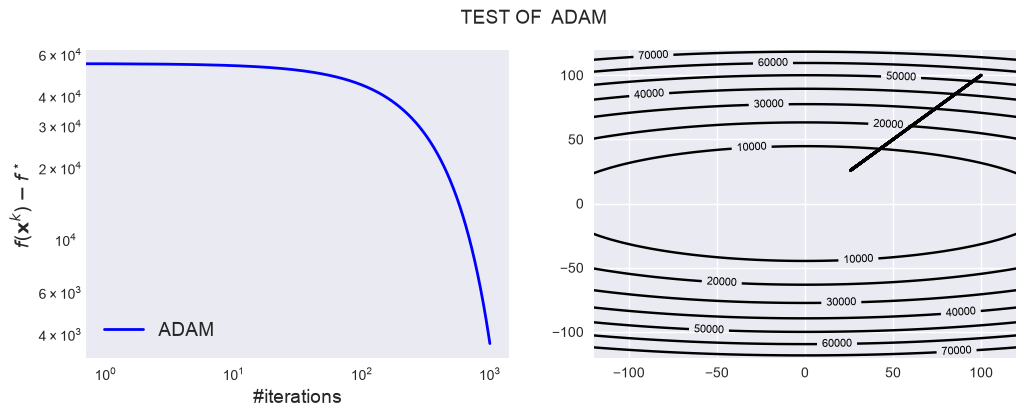

In [46]:
ADAM = OptAlgorithm(name="ADAM", init_state=ADAM_initialize, state_update=ADAM_update)

test(ADAM, maxiter=1000) # need around 3000 

## Schedule-Free Optimizer
Schedule-Free learning replaces the momentum of an underlying optimizer with a combination of interpolation and averaging. In the case of gradient descent, the basic Schedule-Free update is:

$$
\begin{align*}
y_{t} & = (1-\beta)z_{t} + \beta x_{t},\\
z_{t+1} & =z_{t}-\gamma\nabla f_\mu(y_{t}),\\
x_{t+1} & =\left(1-\frac{1}{t+1}\right)x_{t}+\frac{1}{t+1}z_{t+1},
\end{align*}
$$

Evaluate the objective at the averaged iterates $x_t$. The iterates $z_t$ receive the gradient updates, while gradients are evaluated at $y_t$. The updates to $z$ correspond to the underlying optimizer, in this case a simple gradient step.

Schedule-Free learning uses a constant learning rate together with averaging. Its performance depends on the problem and chosen parameters. Only $x_t$ and $z_t$ need to be stored between iterations, since $y_t$ can be computed from them.

Initialize $x_0=z_0$ at `x_zero` and start at $t=0$. Use the constant step size $\gamma=1/L$ and $\beta=0.5$. For the test quadratic, $L=10$, so $\gamma=0.1$.

**(a)** (1 point) Complete the initializer and update for the Schedule-Free optimizer.


In [44]:
@dataclass
class Scheduler_free_state(OptState):
    x_k : Vector
    z_k : Vector
    gamma : float
    beta : float
    k : int
    # FILL
    


In [45]:
def Scheduler_free_update(f, state):
    # FILL
    x_k, z_k, gamma, beta, k = state

    y_k = (1 - beta) * z_k + beta * x_k
    next_z_k = z_k - gamma * f.grad(y_k)
    next_x_k = (1 - 1 / (k + 1)) * x_k + (1 / (k + 1)) * next_z_k

    return Scheduler_free_state(next_x_k, next_z_k, gamma, beta, k + 1)

def Scheduler_free_initialize(f, x_zero):
    # FILL
    x_k = x_zero
    z_k = x_zero
    k = 0
    beta = 0.5
    L = 10
    gamma = 1 / L
    return Scheduler_free_state(x_k, z_k, gamma, beta, k)


**(b)** (1 point) Run your experiment and discuss why the algorithm is referred to as a schedule-free optimizer. You may refer to [The Road Less Scheduled](https://arxiv.org/abs/2405.15682).

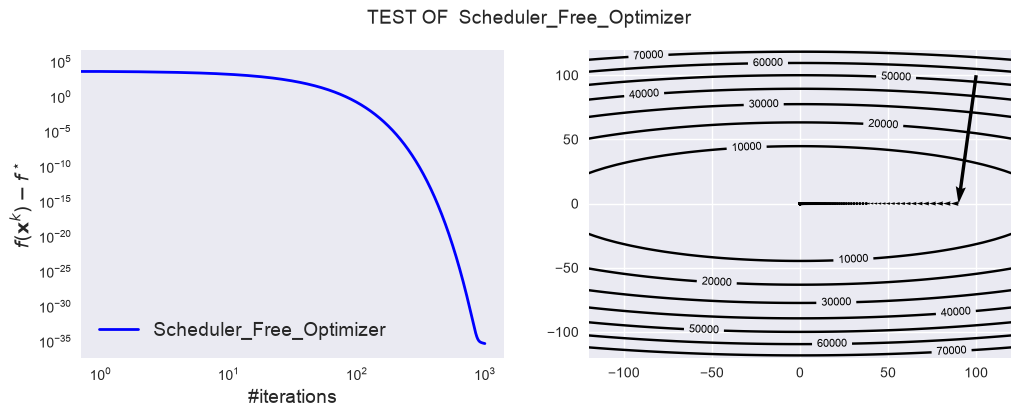

In [46]:
SFO = OptAlgorithm(name="Scheduler_Free_Optimizer", init_state=Scheduler_free_initialize, state_update=Scheduler_free_update)

test(SFO, maxiter=1000)

***Discussion.***

As stated in [The Road Less Scheduled](https://arxiv.org/abs/2405.15682), learning rate schedules that require the specification of the stopping step T greatly outperform the ones that do not depend on it. This is not the case for this proposed Schedule-Free Optimiser which entirely eliminates the learning rate schedule by specifying a learning rate $\gamma$ (in the $z_t$: *base sequence*), and making use of continuous averaging (for $x_t$: *evaluation sequence*) depending on the current number of iterations $t$, plus an interpolation step between $x_t$ and $z_t$ by means of a constant $\beta$. This last step gives the evaluation point for the gradient (*gradient location sequence*). This strategy therefore avoids the need to tune a learning rate scheduler which can be problematic, without needing the stopping time T to be known or set in advance.

## Polyak’s Heavy Ball (PHB) Method

Polyak’s Heavy Ball (PHB) method accelerates gradient descent by adding momentum, modeling a ball rolling over the objective landscape with friction. The continuous-time form is

$$
\ddot{\mathbf{x}} = -a\,\nabla f_\mu(\mathbf{x}) - b\,\dot{\mathbf{x}},
$$

where $a$ controls attraction to the minimum and $b$ provides damping.

The discrete update is

$$
\mathbf{x}_{k+1} = \mathbf{x}_k - \alpha\,\nabla f_\mu(\mathbf{x}_k) + \beta\,(\mathbf{x}_k - \mathbf{x}_{k-1}),
$$

with step size $\alpha$ and momentum $\beta$.

For a strongly convex quadratic with Hessian eigenvalues in $[\mu,L]$, the classical parameter choice is

$$
\alpha = \frac{4}{(\sqrt{L}+\sqrt{\mu})^2}, \qquad 
\beta = \left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^2, \quad \kappa = \frac{L}{\mu},
$$

For these quadratics, the asymptotic convergence factor is

$$
\rho=\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}.
$$

This quadratic result does not guarantee convergence with the same parameters for every smooth, strongly convex objective. On our logistic regression problem, treat this parameter choice as an experiment; momentum can also cause oscillations.

We'll implement PHB with a state that stores the current iterate, the previous iterate, and the scalars $\alpha$ and $\beta$.

**(a)** (1 point) Complete the initializer and update for Polyak’s Heavy Ball optimizer.


In [47]:
@dataclass
class PHB_state(OptState):
    # FILL
    x_k : Vector
    prev_x_k : Vector
    alpha : float
    beta : float


In [48]:
def PHB_update(f, state):
    # FILL
    x_k, prev_x_k, alpha, beta = state
    next_x_k = x_k - alpha * f.grad(x_k) + beta * (x_k - prev_x_k)

    return PHB_state(next_x_k, x_k, alpha, beta) 


def PHB_initialize(f, x_zero):
    # FILL
    x_k = x_zero
    prev_x_k = x_zero ## not sure
    L = f.lips_grad
    mu = f.strng_cvx
    kappa = L / mu
    alpha = 4 / (np.sqrt(L) + np.sqrt(mu))**2
    rho = (np.sqrt(kappa) - 1) / (np.sqrt(kappa) + 1)
    beta = rho ** 2

    return PHB_state(x_k, prev_x_k, alpha, beta)


**(b)** (1 point) Test Polyak’s Heavy Ball optimizer.

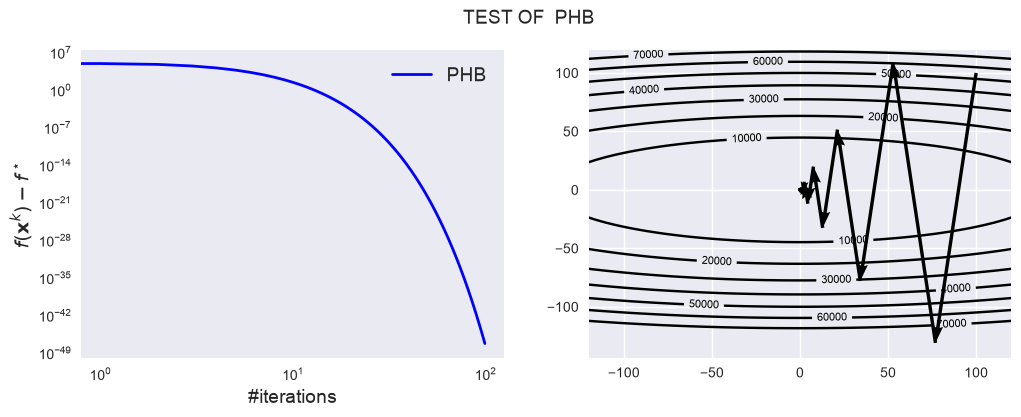

In [49]:
PHB = OptAlgorithm(name="PHB", init_state=PHB_initialize, state_update=PHB_update)

test(PHB)


## NAG-Free Adaptive Acceleration

Here, NAG-Free denotes an adaptive variant of Nesterov’s method that uses line search and local curvature estimates to choose its step size and momentum, without restarts.

Initialize $\mathbf{x}_0=\mathbf{y}_0=$ `x_zero`. Initialize the stored smoothness estimate to `f.lips_grad` and the stored strong-convexity estimate to `f.strng_cvx`; use $1$ and $0$, respectively, if the corresponding value is unavailable or nonpositive. Initialize momentum using the rule below and cache $\nabla f_\mu(\mathbf{y}_0)$.

At iteration $k$, use the following rules:

1. **Line search (`_backtracking_L`).** Starting from half the stored smoothness estimate, double the trial value until
   $$
   f_\mu\!\left(\mathbf{y}_k-\frac{1}{L_k}\nabla f_\mu(\mathbf{y}_k)\right)
   \leq f_\mu(\mathbf{y}_k)-\frac{1}{2L_k}\|\nabla f_\mu(\mathbf{y}_k)\|_2^2.
   $$
   Allow at most 40 doublings; raise `RuntimeError` if the condition still fails. Here $L_k$ denotes the accepted value. Take the gradient step $\mathbf{x}_{k+1}=\mathbf{y}_k-\nabla f_\mu(\mathbf{y}_k)/L_k$.

2. **Local curvature (`_estimate_mu`).** Set $\mathbf{s}_k=\mathbf{x}_{k+1}-\mathbf{x}_k$ and $\mathbf{r}_k=\nabla f_\mu(\mathbf{x}_{k+1})-\nabla f_\mu(\mathbf{x}_k)$. Use
   $$
   \widehat\mu_k=
   \begin{cases}
   \dfrac{\mathbf{s}_k^\top\mathbf{r}_k}{\|\mathbf{s}_k\|_2^2},
      & \|\mathbf{s}_k\|_2^2>0\text{ and }\mathbf{s}_k^\top\mathbf{r}_k>0,\\
   0, & \text{otherwise}.
   \end{cases}
   $$

3. **Momentum (`_momentum_from_L_mu`).** Use
   $$
   a_k=
   \begin{cases}
   \dfrac{\sqrt{L_k}-\sqrt{\widehat\mu_k}}{\sqrt{L_k}+\sqrt{\widehat\mu_k}},
      & L_k>0\text{ and }\widehat\mu_k>0,\\
   0, & \text{otherwise},
   \end{cases}
   \qquad
   \mathbf{y}_{k+1}=\mathbf{x}_{k+1}+a_k(\mathbf{x}_{k+1}-\mathbf{x}_k).
   $$

Store the new iterate, extrapolated point, gradient at that point, and the new estimates $L_k$, $\widehat\mu_k$, and $a_k$ for the next iteration.

Local curvature estimates are not necessarily valid global bounds. This variant should therefore be evaluated experimentally; the accelerated convergence guarantee for AGDstr does not automatically apply to it.

**(a)** (1 point) Complete the cells below to define the state, update rule, initializer, and algorithm object.


In [50]:
@dataclass
class NAGFree_state(OptState):
    # FILL
    x_k : Vector
    y_k : Vector
    grad : Vector
    L_k : float
    mu_k : float
    a_k : float


In [51]:
def _backtracking_L(f, y, g, L_prev):
    # FILL
    L_trial = L_prev / 2
    L_final = None
    i = 0
    while L_final is None :
        left = f(y - g / L_trial) 
        right = f(y) - g@g / (2*L_trial)
        if left <= right :
            L_final = L_trial
        else :
            L_trial*=2
        i+=1
        if i > 40 :
            raise RuntimeError("More than 40 doublings needed")
        
    return L_trial


def _estimate_mu(x_prev, x_cur, g_prev, g_cur):
    # FILL
    s_k = x_cur - x_prev
    r_k = g_cur - g_prev
    num = s_k@r_k
    denom = s_k@s_k
    mu = 0
    if denom > 0 and num > 0 :
        mu = num / denom

    return mu


def _momentum_from_L_mu(L_k, mu_k):
    # FILL
    a_k = 0
    if L_k > 0 and mu_k > 0 :
        a_k = (np.sqrt(L_k) - np.sqrt(mu_k)) / (np.sqrt(L_k) + np.sqrt(mu_k))
    
    return a_k

def NAGFree_update(f, state):
    # FILL
    x_k, y_k, grad_y, L_k, mu_k, a_k = state

    L_k = _backtracking_L(f, y_k, grad_y, L_k)

    next_x_k = y_k - grad_y / L_k

    g_cur = f.grad(next_x_k)
    g_prev = f.grad(x_k)
    mu_k = _estimate_mu(x_k, next_x_k, g_prev, g_cur)

    a_k = _momentum_from_L_mu(L_k, mu_k)
    
    next_y_k = next_x_k + a_k * (next_x_k - x_k)

    return NAGFree_state(next_x_k, next_y_k, f.grad(next_y_k), L_k, mu_k, a_k)
    

def NAGFree_initialize(f, x_zero):
    # FILL
    x_k = x_zero
    y_k = x_zero
    grad_y = f.grad(y_k)
    L_k = f.lips_grad
    mu_k = f.strng_cvx
    if L_k is None or L_k < 0 :
        L_k = 1
    if mu_k is None or mu_k < 0 :
        mu_k = 0
    a_k = _momentum_from_L_mu(L_k, mu_k)

    return NAGFree_state(x_k, y_k, grad_y, L_k, mu_k, a_k)

**(b)** (1 point) Test the NAG-Free adaptive acceleration.

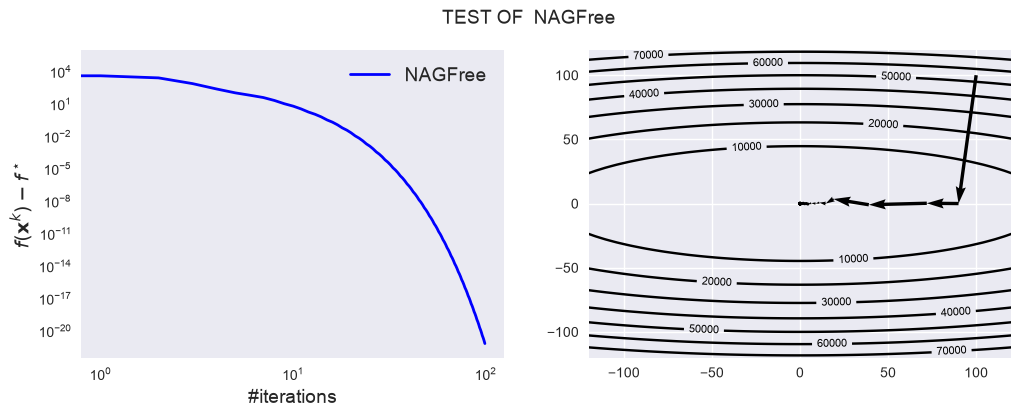

In [52]:
NAGFree = OptAlgorithm(name="NAGFree", init_state=NAGFree_initialize, state_update=NAGFree_update)

test(NAGFree)


## Running the methods - 5 points


We now apply these methods to binary logistic regression, modeling the probability that a basketball shot is successful.

Our data originates from motion tracking data captured by the NBA during the 2015-2016 season.

<img width=50% src='lib/golden_state_shots.png'/>

We consider the `3376` shots made by the Golden State Warriors. The label $b_i$ indicates whether shot $i$ was successful. The five features in $\mathbf{a}_i$ are the shooter’s x- and y-coordinates, distance to the basket, and the minutes and seconds remaining in the quarter.

**(a)** (1 point) Run the following cell to compare the methods you have implemented on the logistic loss:

Scheduler_Free_Optimizer:   0%|          | 0/5000 [00:00<?, ?it/s]/Users/maguettediouf/Documents/Mathematics of Data/Assignment-1-Maths-of-Data/lib/part_one.py:17: RuntimeWarning: overflow encountered in exp
  return np.average(np.log(1 + np.exp(-b * np.dot(A, x)))) + 0.5 * mu * np.dot(x, x)
/Users/maguettediouf/Documents/Mathematics of Data/Assignment-1-Maths-of-Data/lib/part_one.py:12: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-x))
NAGFree: 100%|██████████| 5000/5000 [00:01<00:00, 4279.44it/s]


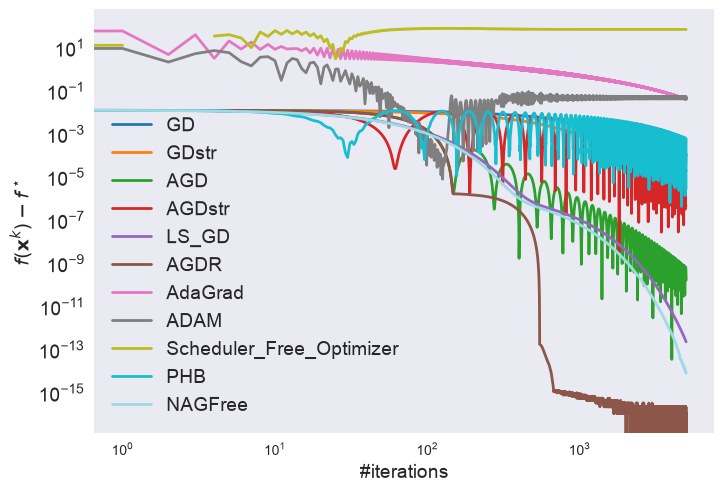

In [53]:
from lib.part_one import f, x_zero, train_accuracy

#Remove methods you have not implemented
methods = [GD, GDstr, AGD, AGDstr, LS_GD, AGDR, AdaGrad, ADAM,SFO, PHB, NAGFree]

plot(methods, f, x_zero, max_iteration=5000, palette="tab20")

**(b)** (2 points) Compare the methods in the plot and discuss whether their observed convergence agrees with the theory.

***Discussion.***

From the plot it is evident that the absolute best performing method in terms of observed convergence rate is Accelerated Gradient Descent with Restart, which maintains steep descent without incurring in the typical oscillation of accelerated methods (it has to be noted, however, that the restart step makes the cost per iteration higher). It is therefore to be expected for this method to show faster convergence than AGD, AGDstr and PHB, with which it shares the same theoretical linear convergence rate. Non-accelerated methods (GD, GDstr and LS_GD) also show slower convergence, although LS_GD seems to perform better than some of the accelerated methods listed above. AdaGrad shows slow, sluggish convergence, performing even worse than regular GD (with which it theoretically shares a sublinear convergence rate of $1/k$). ADAM also shows poorer performance, basically flattening out at the right end of the plot. It is known that, while it is the gold standard for stochastic optimisation, it can fail convergence for some objective functions and is outperformed by deterministic methods in situations in which the objective is $L$-smooth and $\mu$-strongly convex. The scheduler free optimiser apparently completely fails to minimise the objective within the first 5000 iterations, which is underwhelming with respect to the theoretical performance, but it is also said that its performance depends on the problem and chosen parameters.  

Pick the best performing method and run the following cell to display the training accuracy of your solution:

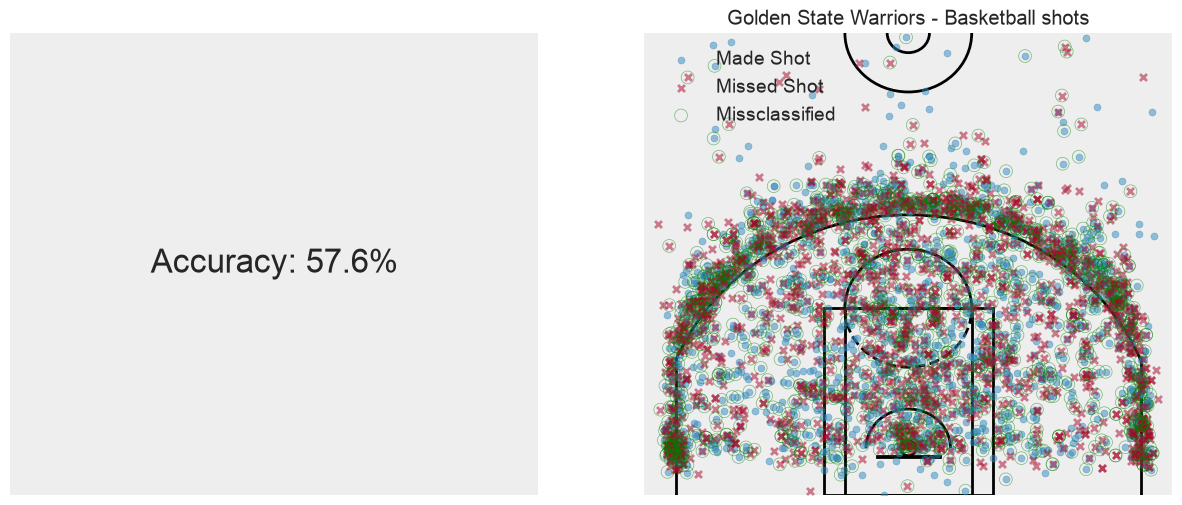

In [54]:
method = AGDR  # FILL: choose a method
run_trace = run(method, f, x_zero, 5000)
last_x_k = run_trace.sequence[-1]

train_accuracy(run_trace.sequence[-1])

**(c)** (2 points) Given we have access to as many as `84467` distinct shots from all teams that played in the 2015–2016 season, how could we use them to improve our model? What effect would this have on the computational cost of our deterministic methods?

***Discussion.***

Using the entire dataset, increasing the number of datapoints from 3376 to 84467, would certainly improve the model, as increasing the size of the training set results in higher accuracy. As a matter of fact, the squared parameter estimation error of the MLE decreases at a rate of $\mathcal{O}(p/n)$ (in general, increasing the number of samples shrinks the statistical error). However, the computational cost per iteration of our deterministic methods would greatly increase, as they would require to compute the exact gradient over the full dataset at every single GD update. This would require longer running time. This exemplifies the so-called "time-data conundrum" that sees algorithm runtime and data as a tradeoff in which the "running time of a learning algorithm increases with the size of the data".

In the next notebook, you will use stochastic methods to reduce the computational cost of a single iteration.